In [2]:
# Recuperamos las fotografías del proyecto de 4Geeks
!mkdir -p /content/data
!wget -q --show-progress -O /content/data/dogs-vs-cats.zip "https://storage.googleapis.com/datascience-materials/dogs-vs-cats.zip"

# Extraemos las imágenes sin pedir confirmaciones
!unzip -nq /content/data/dogs-vs-cats.zip -d /content/data

# Comprobamos la carpeta
!ls /content/data/dogs-vs-cats

/content/data/dogs- 100%[===================>] 554.57M  37.9MB/s    in 15s     
sampleSubmission.csv  train


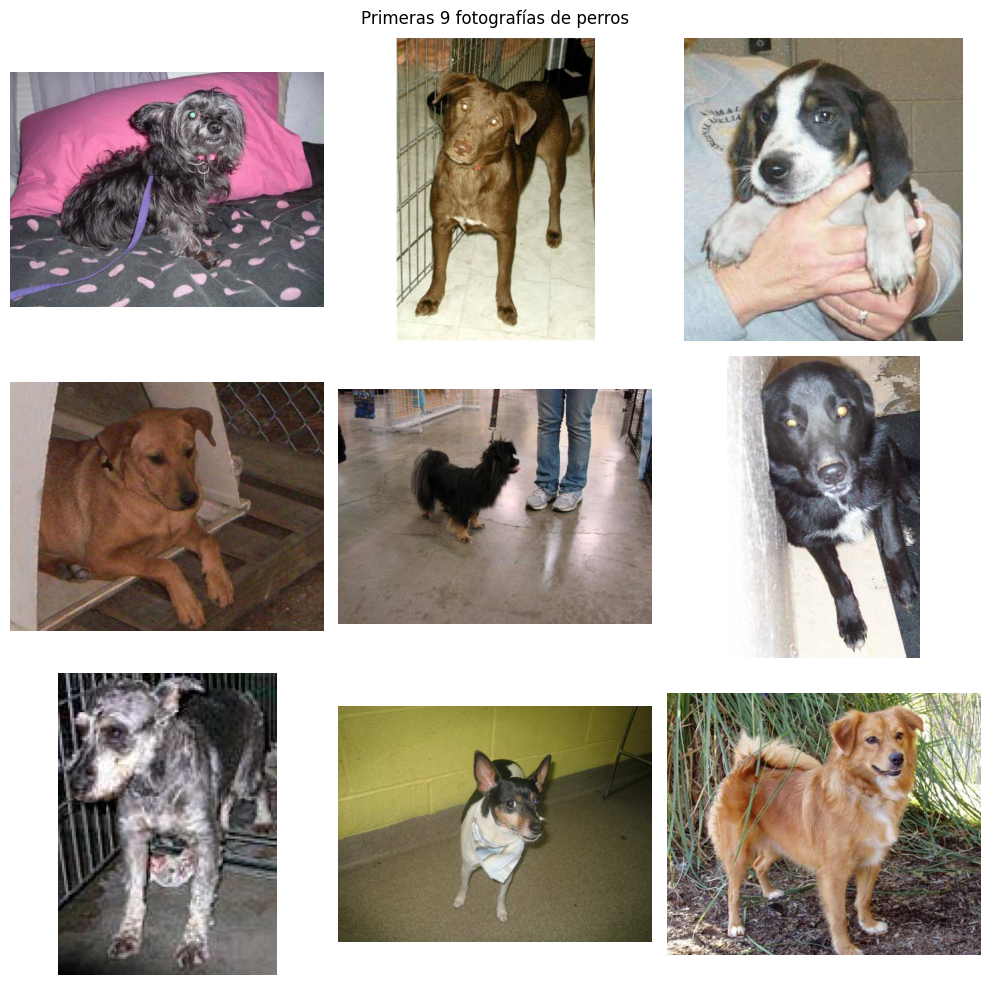

In [12]:
# Cargamos las herramientas para trabajar con imágenes
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# Buscamos las primeras 9 fotografías de perros
carpeta = Path("/content/data/dogs-vs-cats/train")
perros = sorted(carpeta.glob("dog.*.jpg"))[:9]

# Mostramos las 9 fotografías en una misma figura
fig, axes = plt.subplots(3, 3, figsize=(10, 10))

for ax, foto in zip(axes.flat, perros):
    ax.imshow(Image.open(foto))
    ax.axis("off")

plt.suptitle("Primeras 9 fotografías de perros")
plt.tight_layout()
plt.show()

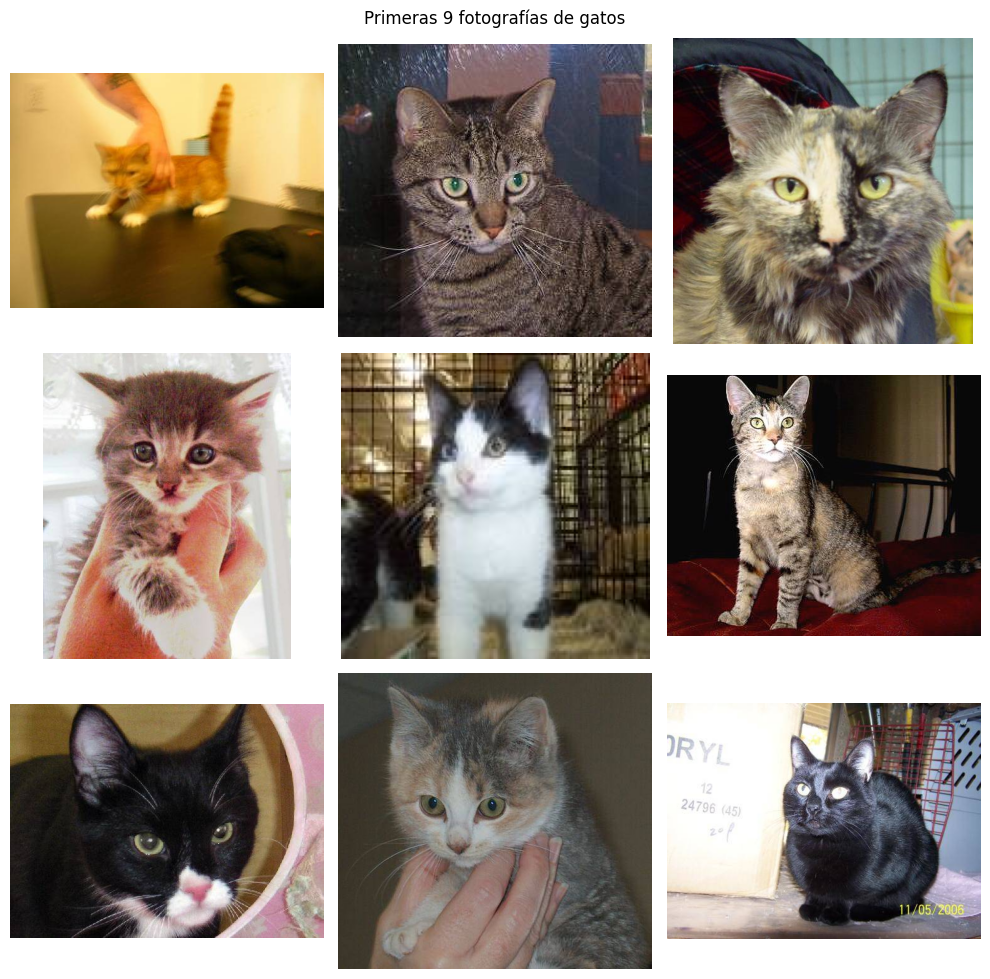

In [13]:
# Buscamos las primeras 9 fotografías de gatos
gatos = sorted(carpeta.glob("cat.*.jpg"))[:9]

# Mostramos las 9 fotografías en una misma figura
fig, axes = plt.subplots(3, 3, figsize=(10, 10))

for ax, foto in zip(axes.flat, gatos):
    ax.imshow(Image.open(foto))
    ax.axis("off")

plt.suptitle("Primeras 9 fotografías de gatos")
plt.tight_layout()
plt.show()


In [3]:
# Recuperamos las carpetas de entrenamiento y prueba
from pathlib import Path
from sklearn.model_selection import train_test_split

carpeta = Path("/content/data/dogs-vs-cats/train")
imagenes = sorted(carpeta.glob("*.jpg"))

train, test = train_test_split(
    imagenes,
    test_size=0.2,
    random_state=42,
    stratify=[foto.name.split(".")[0] for foto in imagenes]
)

# Organizamos las imágenes sin duplicarlas
for grupo, fotos in [("train", train), ("test", test)]:
    for foto in fotos:
        animal = foto.name.split(".")[0]
        destino = Path("/content/data/processed") / grupo / animal
        destino.mkdir(parents=True, exist_ok=True)

        enlace = destino / foto.name
        if not enlace.exists():
            enlace.symlink_to(foto)

print("Entrenamiento:", len(train))
print("Prueba:", len(test))

Entrenamiento: 20000
Prueba: 5000


In [5]:
# Preparamos las imágenes para entrenar y validar
from tensorflow.keras.preprocessing.image import ImageDataGenerator

generador = ImageDataGenerator(validation_split=0.2)

# Imágenes de entrenamiento
trdata = generador.flow_from_directory(
    "/content/data/processed/train",
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    subset="training"
)

# Imágenes de validación
valdata = generador.flow_from_directory(
    "/content/data/processed/train",
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    subset="validation"
)

# Imágenes para la prueba final
tsdata = ImageDataGenerator().flow_from_directory(
    "/content/data/processed/test",
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    shuffle=False
)

Found 16000 images belonging to 2 classes.
Found 4000 images belonging to 2 classes.
Found 5000 images belonging to 2 classes.


In [16]:
# Creamos nuestra red neuronal para reconocer perros y gatos
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D

model = Sequential()

# Red que aprende las características de las imágenes
model.add(EfficientNetB0(
    include_top=False,
    weights=None,
    input_shape=(224, 224, 3)
))

# Preparamos la información obtenida de las imágenes
model.add(GlobalAveragePooling2D())

# Añadimos las capas que decidirán si es perro o gato
model.add(Dense(units=128, activation="relu"))
model.add(Dense(units=2, activation="softmax"))

# Vemos cómo está construida nuestra red neuronal
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,797 (16.07 MB)

 Trainable params: 4,171,774 (15.91 MB)

 Non-trainable params: 42,023 (164.16 KB)

In [17]:
# Preparamos la red neuronal para su entrenamiento
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Modelo preparado para entrenar")

Modelo preparado para entrenar


In [ ]:
# Probamos el entrenamiento de nuestra red neuronal
historial = model.fit(
    trdata,
    epochs=1,
    steps_per_epoch=1
)

In [ ]:
# Comprobamos cuántas imágenes procesa la red en cada lote
print("Imágenes por lote:", trdata.batch_size)

In [18]:
# Reservamos parte del entrenamiento para validar el modelo
generador_validacion = ImageDataGenerator(validation_split=0.2)

# Imágenes que utilizará la red para aprender
trdata = generador_validacion.flow_from_directory(
    "/content/data/processed/train",
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    subset="training"
)

# Imágenes para comprobar cómo está aprendiendo
valdata = generador_validacion.flow_from_directory(
    "/content/data/processed/train",
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    subset="validation",
    shuffle=False
)

Found 16000 images belonging to 2 classes.
Found 4000 images belonging to 2 classes.


In [19]:
# Preparamos las herramientas para mejorar el entrenamiento
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Detenemos el entrenamiento si el modelo deja de mejorar
parada = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Guardamos automáticamente el mejor modelo
guardar = ModelCheckpoint(
    "/content/mejor_modelo.keras",
    monitor="val_loss",
    save_best_only=True
)

print("Herramientas de entrenamiento preparadas")

Herramientas de entrenamiento preparadas


In [20]:
# Entrenamos nuestra red neuronal con una cantidad reducida de imágenes
historial = model.fit(
    trdata,
    validation_data=valdata,
    epochs=2,
    steps_per_epoch=5,
    validation_steps=2,
    callbacks=[parada, guardar]
)

Epoch 1/2
5/5 ━━━━━━━━━━━━━━━━━━━━ 138s 19s/step - accuracy: 0.5625 - loss: 0.8493 - val_accuracy: 1.0000 - val_loss: 0.6852
Epoch 2/2
5/5 ━━━━━━━━━━━━━━━━━━━━ 83s 18s/step - accuracy: 0.5437 - loss: 0.6651 - val_accuracy: 1.0000 - val_loss: 0.6787


In [21]:
# Guardamos la red neuronal que hemos entrenado
model.save("/content/modelo_clasificador.keras")

# Preparamos una muestra aleatoria de imágenes de prueba
prueba = ImageDataGenerator().flow_from_directory(
    "/content/data/processed/test",
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    shuffle=True,
    seed=42
)

# Comprobamos el rendimiento con imágenes nuevas
loss_test, accuracy_test = model.evaluate(prueba, steps=4)

print("Accuracy de prueba:", round(accuracy_test * 100, 2), "%")
print("Modelo guardado correctamente")

Found 5000 images belonging to 2 classes.
4/4 ━━━━━━━━━━━━━━━━━━━━ 11s 2s/step - accuracy: 0.4844 - loss: 0.6937
Accuracy de prueba: 48.44 %
Modelo guardado correctamente


In [1]:
# Comprobamos la GPU y los archivos del proyecto
import tensorflow as tf
from pathlib import Path

print("GPU:", tf.config.list_physical_devices("GPU"))
print("Fotografías:", Path("/content/data/dogs-vs-cats/train").exists())
print("Datos preparados:", Path("/content/data/processed/train").exists())
print("Modelo guardado:", Path("/content/modelo_clasificador.keras").exists())

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Fotografías: False
Datos preparados: False
Modelo guardado: False


In [8]:
# Recuperamos el modelo que ya habíamos entrenado
from tensorflow.keras.models import load_model

model = load_model("/content/modelo_clasificador.keras")

print("Modelo recuperado correctamente")

Modelo recuperado correctamente


In [7]:
# Buscamos dónde se ha guardado nuestro modelo
!find /content -name "*.keras"


/content/modelo_clasificador.keras


In [9]:
# Continuamos entrenando nuestro modelo con la GPU
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Guardamos la mejor versión y evitamos entrenar de más
parada = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

guardar = ModelCheckpoint(
    "/content/mejor_modelo.keras",
    monitor="val_loss",
    save_best_only=True
)

# Entrenamos con más imágenes que en la prueba anterior
historial = model.fit(
    trdata,
    validation_data=valdata,
    epochs=3,
    steps_per_epoch=20,
    validation_steps=4,
    callbacks=[parada, guardar]
)

Epoch 1/3
20/20 ━━━━━━━━━━━━━━━━━━━━ 47s 613ms/step - accuracy: 0.5422 - loss: 0.8017 - val_accuracy: 0.4844 - val_loss: 0.7065
Epoch 2/3
20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 433ms/step - accuracy: 0.5094 - loss: 0.8005 - val_accuracy: 0.4844 - val_loss: 0.6955
Epoch 3/3
20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 437ms/step - accuracy: 0.5234 - loss: 0.7313 - val_accuracy: 0.4922 - val_loss: 0.6949


In [10]:
# Recuperamos el mejor modelo que se haya guardado
from pathlib import Path
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator

ruta = Path("/content/mejor_modelo.keras")

if ruta.exists():
    model = load_model(ruta)

# Evaluamos con una muestra aleatoria de imágenes de prueba
prueba = ImageDataGenerator().flow_from_directory(
    "/content/data/processed/test",
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    shuffle=True,
    seed=42
)

loss, accuracy = model.evaluate(prueba, steps=10)

# Guardamos nuestro modelo final
model.save("/content/modelo_clasificador_final.keras")

print("Accuracy final:", round(accuracy * 100, 2), "%")
print("Modelo final guardado")

Found 5000 images belonging to 2 classes.
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 106ms/step - accuracy: 0.5094 - loss: 0.6933
Accuracy final: 50.94 %
Modelo final guardado
